# Comparing 6 Federated Learning Algorithms on CIFAR-10

One dataset (CIFAR-10), one Non-IID client split, one model architecture for every client — the **only**
thing that changes is the federated algorithm. This isolates the effect of the algorithm itself.

| # | Algorithm | Idea |
|---|---|---|
| 1 | **FedAvg** | Plain weighted average of client weights (baseline) |
| 2 | **FedProx** | FedAvg + a penalty term that stops local models drifting too far from the global model |
| 3 | **FedAdagrad** | Server treats the aggregated update as a gradient and applies Adagrad (adaptive, accumulating) |
| 4 | **FedYogi** | Server-side adaptive optimizer, more stable than Adagrad on Non-IID data |
| 5 | **FedAdam** | Server-side Adam optimizer applied to the aggregated update |
| 6 | **FedDistillation (FedDF)** | Clients don't share weights at all — they share *predictions* on a small public proxy set, and the server distills those into the global model |

FedAvg, FedProx, FedAdagrad, FedYogi and FedAdam all average/combine **model weights**, so they need
identical architectures across clients (satisfied here). FedDistillation doesn't strictly need that, but we
keep it on the same architecture too so the comparison stays fair.

---
## Section 1: Imports & Device Setup

In [1]:
import sys
!{sys.executable} -m pip install -q torch torchvision

In [2]:
import torch, torch.nn as nn, torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision, torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device  : {DEVICE}')
print(f'PyTorch : {torch.__version__}')

Device  : cpu
PyTorch : 2.11.0+cpu


---
## Section 2: Configuration

In [3]:
CONFIG = {
    'num_clients'    : 3,
    'num_rounds'     : 10,
    'local_epochs'   : 5,
    'batch_size'     : 64,
    'learning_rate'  : 0.001,
    'non_iid_alpha'  : 0.5,
    'temperature'    : 4.0,
    'num_public'     : 500,
    'distill_epochs' : 10,
    'mu_prox'        : 0.01,
    'server_lr'      : 0.1,
    'beta1'          : 0.9,
    'beta2'          : 0.99,
    'tau'            : 1e-3,
}
CIFAR10_CLASSES = ['Airplane','Automobile','Bird','Cat','Deer',
                   'Dog','Frog','Horse','Ship','Truck']
print('Configuration loaded')
for k, v in CONFIG.items(): print(f'   {k}: {v}')

Configuration loaded
   num_clients: 3
   num_rounds: 10
   local_epochs: 5
   batch_size: 64
   learning_rate: 0.001
   non_iid_alpha: 0.5
   temperature: 4.0
   num_public: 500
   distill_epochs: 10
   mu_prox: 0.01
   server_lr: 0.1
   beta1: 0.9
   beta2: 0.99
   tau: 0.001


---
## Section 3: CIFAR-10 Dataset (Non-IID split across 3 clients)

In [ ]:
np.random.seed(42); torch.manual_seed(42)

transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.4914,0.4822,0.4465),(0.2023,0.1994,0.2010))
])
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914,0.4822,0.4465),(0.2023,0.1994,0.2010))
])

train_data = torchvision.datasets.CIFAR10('.', train=True,  download=True, transform=transform_train)
test_data  = torchvision.datasets.CIFAR10('.', train=False, download=True, transform=transform_test)

def dirichlet_split(dataset, num_clients, alpha=0.5):
    """Non-IID Dirichlet split - Hsu et al. (2019). Standard FL benchmark."""
    labels = np.array(dataset.targets)
    client_indices = [[] for _ in range(num_clients)]
    for cls in range(10):
        idx = np.where(labels == cls)[0]; np.random.shuffle(idx)
        props = np.random.dirichlet(np.repeat(alpha, num_clients))
        splits = (props * len(idx)).astype(int)
        splits[-1] = len(idx) - splits[:-1].sum()
        start = 0
        for i, count in enumerate(splits):
            client_indices[i].extend(idx[start:start+count].tolist()); start += count
    return client_indices

client_indices = dirichlet_split(train_data, CONFIG['num_clients'], CONFIG['non_iid_alpha'])

public_loader  = DataLoader(Subset(test_data, list(range(CONFIG['num_public']))),
                            batch_size=CONFIG['num_public'], shuffle=False)
test_loader    = DataLoader(test_data, batch_size=256, shuffle=False)
client_loaders = [DataLoader(Subset(train_data, client_indices[i]),
                             batch_size=CONFIG['batch_size'], shuffle=True)
                  for i in range(CONFIG['num_clients'])]

print(f'CIFAR-10: {len(train_data)} train | {len(test_data)} test | 10 object classes')
print(f'Non-IID Dirichlet split (alpha={CONFIG["non_iid_alpha"]}):')
for i, idx in enumerate(client_indices):
    lbls = np.array(train_data.targets)[idx]
    u, c = np.unique(lbls, return_counts=True)
    class_dist = {CIFAR10_CLASSES[k]: int(v) for k,v in zip(u,c)}
    print(f'   Client {i+1}: {len(idx)} samples | {class_dist}')
print(f'Public proxy for FedDistillation: {CONFIG["num_public"]} samples')

100%|██████████| 170M/170M [37:13<00:00, 76.3kB/s]


CIFAR-10: 50000 train | 10000 test | 10 object classes
Non-IID Dirichlet split (alpha=0.5):
   Client 1: 10248 samples | {'Airplane': 483, 'Automobile': 140, 'Bird': 104, 'Cat': 62, 'Deer': 1123, 'Dog': 1531, 'Frog': 75, 'Horse': 1491, 'Ship': 1801, 'Truck': 3438}
   Client 2: 26096 samples | {'Airplane': 3979, 'Automobile': 4859, 'Bird': 4281, 'Cat': 3467, 'Deer': 803, 'Dog': 1269, 'Frog': 1841, 'Horse': 1976, 'Ship': 2200, 'Truck': 1421}
   Client 3: 13656 samples | {'Airplane': 538, 'Automobile': 1, 'Bird': 615, 'Cat': 1471, 'Deer': 3074, 'Dog': 2200, 'Frog': 3084, 'Horse': 1533, 'Ship': 999, 'Truck': 141}
Public proxy for FedDistillation: 500 samples


---
## Section 4: Model Architecture (same for every client)

In [ ]:
class MediumCNN(nn.Module):
    """Used identically by every client, in every algorithm - fair comparison."""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(64*8*8, 128), nn.ReLU(),
            nn.Linear(128, 10)
        )
    def forward(self, x): return self.net(x)

n_params = sum(p.numel() for p in MediumCNN().parameters())
print(f'MediumCNN: {n_params:,} parameters (identical for all clients, all 6 algorithms)')

MediumCNN: 545,098 parameters (identical for all clients, all 6 algorithms)


---
## Section 5: Helper Functions

In [ ]:
def train_local(model, loader, optimizer, epochs, device):
    """Standard local training on hard labels only."""
    model.train()
    ce = nn.CrossEntropyLoss()
    for _ in range(epochs):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            ce(model(imgs), labels).backward()
            optimizer.step()

def train_local_fedprox(model, loader, optimizer, epochs, device, global_state, mu):
    """Same as train_local, but adds the FedProx proximal term (mu/2)*||w_local - w_global||^2."""
    model.train()
    ce = nn.CrossEntropyLoss()
    global_params = {k: v.clone().detach().to(device) for k, v in global_state.items()}
    for _ in range(epochs):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = ce(model(imgs), labels)
            prox = sum(((p - global_params[n]) ** 2).sum()
                       for n, p in model.named_parameters() if n in global_params)
            (loss + (mu / 2) * prox).backward()
            optimizer.step()

def evaluate_model(model, loader, device):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            correct += (model(imgs).argmax(1) == labels).sum().item()
            total   += labels.size(0)
    return correct / total

def get_soft_preds(model, public_X, device):
    model.eval()
    with torch.no_grad():
        return F.softmax(model(public_X.to(device)), dim=1).cpu()

def weighted_avg_state(models, sizes):
    """Plain FedAvg-style weighted average of state_dicts."""
    total = sum(sizes)
    keys = models[0].state_dict().keys()
    return {k: sum(models[i].state_dict()[k].float() * (sizes[i] / total) for i in range(len(models)))
            for k in keys}

def fedopt_server_update(global_model, avg_state, server_state, algo, cfg):
    """
    FedOpt-style server update (Reddi et al., 2021).
    delta = avg_client_weights - global_weights  (the 'pseudo-gradient')
    algo in {'fedavg', 'fedadagrad', 'fedyogi', 'fedadam'}
    server_state carries the running m (momentum) and v (2nd moment) per parameter tensor.
    """
    g_state = global_model.state_dict()
    new_state = {}
    for key in g_state:
        delta = avg_state[key].float() - g_state[key].float()
        if algo == 'fedavg':
            new_state[key] = g_state[key].float() + delta          # = avg_state, plain FedAvg
            continue
        if key not in server_state:
            server_state[key] = {'m': torch.zeros_like(delta), 'v': torch.full_like(delta, cfg['tau'] ** 2)}
        m, v = server_state[key]['m'], server_state[key]['v']
        if algo == 'fedadagrad':
            v = v + delta ** 2
        elif algo == 'fedyogi':
            m = cfg['beta1'] * m + (1 - cfg['beta1']) * delta
            v = v - (1 - cfg['beta2']) * torch.sign(v - delta ** 2) * (delta ** 2)
        elif algo == 'fedadam':
            m = cfg['beta1'] * m + (1 - cfg['beta1']) * delta
            v = cfg['beta2'] * v + (1 - cfg['beta2']) * (delta ** 2)
        else:
            raise ValueError(algo)
        update = m if algo != 'fedadagrad' else delta
        server_state[key] = {'m': m, 'v': v}
        new_state[key] = g_state[key].float() + cfg['server_lr'] * update / (torch.sqrt(v) + cfg['tau'])
    return new_state

print('Helper functions ready')

Helper functions ready


---
## Section 6: Run FedAvg, FedProx, FedAdagrad, FedYogi, FedAdam

In [ ]:
def run_weight_based_algo(algo_name, use_prox=False):
    """Runs FedAvg / FedProx / FedAdagrad / FedYogi / FedAdam - all weight-averaging algorithms,
    on the identical CIFAR-10 Non-IID client split and MediumCNN architecture."""
    label = 'FedProx' if use_prox else algo_name.upper()
    print('='*60); print(f'  {label}'); print('='*60)

    clients = [MediumCNN().to(DEVICE) for _ in range(CONFIG['num_clients'])]
    opts    = [optim.Adam(m.parameters(), lr=CONFIG['learning_rate']) for m in clients]
    global_model = MediumCNN().to(DEVICE)
    server_state = {}
    sizes = [len(idx) for idx in client_indices]
    history = {'round': [], 'global_acc': []}

    for rnd in range(1, CONFIG['num_rounds'] + 1):
        g_state = global_model.state_dict()
        for c in clients:
            c.load_state_dict(g_state)

        for c, opt, loader in zip(clients, opts, client_loaders):
            if use_prox:
                train_local_fedprox(c, loader, opt, CONFIG['local_epochs'], DEVICE, g_state, CONFIG['mu_prox'])
            else:
                train_local(c, loader, opt, CONFIG['local_epochs'], DEVICE)

        avg_state = weighted_avg_state(clients, sizes)
        new_state = fedopt_server_update(global_model, avg_state, server_state, algo_name, CONFIG)
        global_model.load_state_dict(new_state)

        acc = evaluate_model(global_model, test_loader, DEVICE)
        history['round'].append(rnd); history['global_acc'].append(acc)
        print(f'  Round {rnd:02d} | Global Accuracy: {acc:.4f}')
    print(f'Final: {history["global_acc"][-1]:.4f}\n')
    return history

# 1. FedAvg
history_fedavg     = run_weight_based_algo('fedavg')
# 2. FedProx  (aggregation = plain FedAvg update, local objective has the proximal penalty)
history_fedprox    = run_weight_based_algo('fedavg', use_prox=True)
# 3. FedAdagrad
history_fedadagrad = run_weight_based_algo('fedadagrad')
# 4. FedYogi
history_fedyogi    = run_weight_based_algo('fedyogi')
# 5. FedAdam
history_fedadam    = run_weight_based_algo('fedadam')

  FEDAVG
  Round 01 | Global Accuracy: 0.5807
  Round 02 | Global Accuracy: 0.6194
  Round 03 | Global Accuracy: 0.6706
  Round 04 | Global Accuracy: 0.6954
  Round 05 | Global Accuracy: 0.7279
  Round 06 | Global Accuracy: 0.7396
  Round 07 | Global Accuracy: 0.7578
  Round 08 | Global Accuracy: 0.7620
  Round 09 | Global Accuracy: 0.7632
  Round 10 | Global Accuracy: 0.7645
Final: 0.7645

  FedProx
  Round 01 | Global Accuracy: 0.5295
  Round 02 | Global Accuracy: 0.6156
  Round 03 | Global Accuracy: 0.6726
  Round 04 | Global Accuracy: 0.6883
  Round 05 | Global Accuracy: 0.7143
  Round 06 | Global Accuracy: 0.7166
  Round 07 | Global Accuracy: 0.7220
  Round 08 | Global Accuracy: 0.7374
  Round 09 | Global Accuracy: 0.7435
  Round 10 | Global Accuracy: 0.7438
Final: 0.7438

  FEDADAGRAD
  Round 01 | Global Accuracy: 0.2353
  Round 02 | Global Accuracy: 0.1170
  Round 03 | Global Accuracy: 0.3470
  Round 04 | Global Accuracy: 0.3927
  Round 05 | Global Accuracy: 0.5586
  Round 06 | 

---
## Section 7: Run FedDistillation (FedDF)

In [ ]:
# 6. FedDistillation (FedDF) - clients share PREDICTIONS on a small public proxy set, not weights.
print('='*60); print('  FEDDISTILLATION (FedDF)'); print('='*60)

clients_fd = [MediumCNN().to(DEVICE) for _ in range(CONFIG['num_clients'])]
opts_fd    = [optim.Adam(m.parameters(), lr=CONFIG['learning_rate']) for m in clients_fd]
global_fd  = MediumCNN().to(DEVICE)
sizes      = [len(idx) for idx in client_indices]
public_X_fd, _ = next(iter(public_loader))
history_feddistill = {'round': [], 'global_acc': []}

for rnd in range(1, CONFIG['num_rounds'] + 1):
    # 1) each client trains locally on its own private data only
    for c, opt, loader in zip(clients_fd, opts_fd, client_loaders):
        train_local(c, loader, opt, CONFIG['local_epochs'], DEVICE)

    # 2) server collects each client's SOFT PREDICTIONS on the shared public proxy set
    client_soft_preds = [get_soft_preds(c, public_X_fd, DEVICE) for c in clients_fd]
    weights = np.array(sizes) / sum(sizes)
    ensemble_soft = sum(w * p for w, p in zip(weights, client_soft_preds))   # weighted ensemble = teacher

    # 3) global model distills the ensemble's knowledge (no weight averaging at all)
    global_opt = optim.Adam(global_fd.parameters(), lr=CONFIG['learning_rate'])
    for _ in range(CONFIG['distill_epochs']):
        global_opt.zero_grad()
        logits = global_fd(public_X_fd.to(DEVICE))
        T = CONFIG['temperature']
        s_log  = F.log_softmax(logits / T, dim=1)
        t_soft = F.softmax(ensemble_soft.to(DEVICE) / T, dim=1)
        (nn.KLDivLoss(reduction='batchmean')(s_log, t_soft) * (T ** 2)).backward()
        global_opt.step()

    # 4) broadcast the newly-distilled global model back down so next round's local training starts from it
    for c in clients_fd:
        c.load_state_dict(global_fd.state_dict())

    acc = evaluate_model(global_fd, test_loader, DEVICE)
    history_feddistill['round'].append(rnd)
    history_feddistill['global_acc'].append(acc)
    print(f'  Round {rnd:02d} | Global Accuracy: {acc:.4f}')

print(f'Final: {history_feddistill["global_acc"][-1]:.4f}')

  FEDDISTILLATION (FedDF)
  Round 01 | Global Accuracy: 0.1149
  Round 02 | Global Accuracy: 0.2580
  Round 03 | Global Accuracy: 0.3273
  Round 04 | Global Accuracy: 0.3899
  Round 05 | Global Accuracy: 0.3873
  Round 06 | Global Accuracy: 0.3996
  Round 07 | Global Accuracy: 0.4056
  Round 08 | Global Accuracy: 0.4301
  Round 09 | Global Accuracy: 0.4257
  Round 10 | Global Accuracy: 0.4427
Final: 0.4427


---
## Section 8: Compare All 6 Algorithms

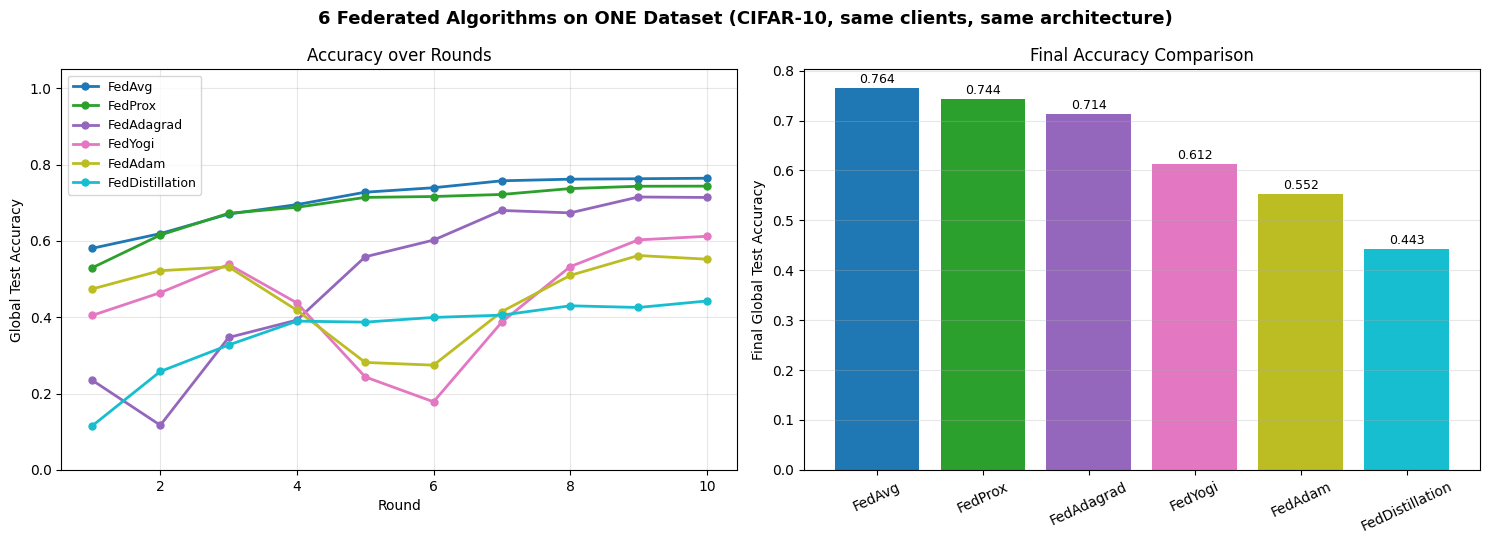

Saved as six_algo_comparison.png

Final ranking:
   FedAvg            : 0.7645
   FedProx           : 0.7438
   FedAdagrad        : 0.7141
   FedYogi           : 0.6123
   FedAdam           : 0.5523
   FedDistillation   : 0.4427


In [ ]:
results = {
    'FedAvg'          : history_fedavg,
    'FedProx'         : history_fedprox,
    'FedAdagrad'      : history_fedadagrad,
    'FedYogi'         : history_fedyogi,
    'FedAdam'         : history_fedadam,
    'FedDistillation' : history_feddistill,
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
fig.suptitle('6 Federated Algorithms on ONE Dataset (CIFAR-10, same clients, same architecture)',
             fontsize=13, fontweight='bold')

palette = plt.cm.tab10(np.linspace(0, 1, 6))
for (name, hist), color in zip(results.items(), palette):
    axes[0].plot(hist['round'], hist['global_acc'], '-o', lw=2, ms=5, color=color, label=name)
axes[0].set(xlabel='Round', ylabel='Global Test Accuracy', title='Accuracy over Rounds')
axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3); axes[0].set_ylim(0, 1.05)

final_accs = [hist['global_acc'][-1] for hist in results.values()]
bars = axes[1].bar(list(results.keys()), final_accs, color=palette)
axes[1].set(ylabel='Final Global Test Accuracy', title='Final Accuracy Comparison')
axes[1].tick_params(axis='x', rotation=25); axes[1].grid(alpha=0.3, axis='y')
for b, a in zip(bars, final_accs):
    axes[1].text(b.get_x() + b.get_width()/2, a + 0.01, f'{a:.3f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('six_algo_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved as six_algo_comparison.png')

print('\nFinal ranking:')
for name, acc in sorted(zip(results.keys(), final_accs), key=lambda x: -x[1]):
    print(f'   {name:18s}: {acc:.4f}')

---
## Section 9: Summary

**What's identical across all 6 runs:** dataset (CIFAR-10), client data split (same Non-IID Dirichlet
split), model architecture (`MediumCNN` for every client), number of rounds, and local epochs. The
**only** thing that changes between runs is the federated algorithm itself - so any accuracy difference
you see is caused by the algorithm, not by a different setup.

**How to describe each one in plain words:**
- **FedAvg** - every client sends its trained model back, the server just averages them by how much data each client has.
- **FedProx** - same as FedAvg, but while training locally each client is penalized for straying too far from the global model - this helps a lot when clients have very different (Non-IID) data.
- **FedAdagrad** - the server treats the "distance moved" as a gradient and applies Adagrad, so parameters that keep changing a lot get smaller updates over time.
- **FedYogi** - similar server-side idea but a more controlled/stable version of Adagrad, usually better for Non-IID data.
- **FedAdam** - the server applies the well-known Adam optimizer to the aggregated update instead of just adding it directly.
- **FedDistillation (FedDF)** - the most different one: clients never send their weights at all. They only send their *predictions* on a small shared public dataset, and the server trains the global model to imitate the combined ("ensembled") predictions. This is the only method here that would still work even if clients had different model architectures.

The bar chart above shows which algorithm reached the highest final accuracy on this dataset/split - report
that ranking together with the plain-word descriptions above.